# Projeto Final — Etapa 2: Desenvolvimento e Avaliação dos Modelos

## Etapa 2 — Código da Solução

Nesta etapa será implementado o processo de preparação, treinamento e avaliação dos modelos de classificação para previsão de churn.

O objetivo é desenvolver uma solução reproduzível capaz de identificar clientes com maior probabilidade de cancelamento, utilizando apenas informações que estariam disponíveis no momento da previsão.

A AUC-ROC será utilizada como principal métrica de comparação entre os modelos. Métricas complementares também serão analisadas para avaliar diferentes tipos de erro e sua possível relevância para as estratégias de retenção da Interconnect.

## 7. Preparação dos dados para modelagem

Antes do treinamento dos modelos, será construída uma base contendo apenas características adequadas para previsão.

Variáveis que fornecem diretamente informações sobre o encerramento do contrato ou que foram construídas utilizando informações posteriores ao cancelamento serão removidas para evitar vazamento de dados (*data leakage*).

A variável `Churn` será utilizada como alvo da classificação.

In [48]:
# Criando uma cópia da base integrada para a etapa de modelagem

model_data = data.copy()

print('Dimensão da base:', model_data.shape)
model_data.head()

Dimensão da base: (7043, 24)


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,EndDate_dt,FinalDate,TenureMonths,gender,SeniorCitizen,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,NaT,2020-02-01,1,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,No phone
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.50,0,NaT,2020-02-01,34,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1,2019-12-01,2019-12-01,2,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,NaT,2020-02-01,45,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,No phone
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1,2019-11-01,2019-11-01,2,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No


In [49]:
# Verificando as colunas e os tipos de dados da base de modelagem

print('Colunas disponíveis para análise:\n')

for column in model_data.columns:
    print(f'{column:<25} {str(model_data[column].dtype)}')

Colunas disponíveis para análise:

customerID                object
BeginDate                 datetime64[ns]
EndDate                   object
Type                      object
PaperlessBilling          object
PaymentMethod             object
MonthlyCharges            float64
TotalCharges              float64
Churn                     int64
EndDate_dt                datetime64[ns]
FinalDate                 datetime64[ns]
TenureMonths              int64
gender                    object
SeniorCitizen             int64
Partner                   object
Dependents                object
InternetService           object
OnlineSecurity            object
OnlineBackup              object
DeviceProtection          object
TechSupport               object
StreamingTV               object
StreamingMovies           object
MultipleLines             object


### Seleção das características para modelagem

Antes da divisão dos dados, serão removidas variáveis que não devem ser utilizadas como características preditoras.

- `customerID`: identificador único do cliente, sem significado preditivo direto;
- `EndDate` e `EndDate_dt`: contêm informação direta sobre o cancelamento e causariam vazamento de dados;
- `FinalDate`: foi construída utilizando a data de cancelamento para clientes que apresentaram churn;
- `TenureMonths`: embora seja relevante para a análise exploratória, sua construção atual utiliza `EndDate` para clientes que cancelaram e, portanto, pode introduzir informação posterior ao evento que se deseja prever.

A variável `BeginDate` contém informação legítima disponível antes do cancelamento, mas não será utilizada diretamente como uma data bruta. Sua possível transformação em uma característica temporal será avaliada considerando uma data de referência comum, de forma a evitar vazamento de dados.

A variável `Churn` será mantida exclusivamente como variável-alvo.

In [50]:
# Removendo identificadores e variáveis com risco de vazamento de dados

columns_to_drop = [
    'customerID',
    'EndDate',
    'EndDate_dt',
    'FinalDate',
    'TenureMonths'
]

model_data_clean = model_data.drop(columns=columns_to_drop).copy()

print('Dimensão antes da remoção:', model_data.shape)
print('Dimensão após a remoção:', model_data_clean.shape)

print('\nColunas restantes:')
print(model_data_clean.columns.tolist())

Dimensão antes da remoção: (7043, 24)
Dimensão após a remoção: (7043, 19)

Colunas restantes:
['BeginDate', 'Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']


### Tratamento da variável temporal `BeginDate`

A variável `BeginDate` representa a data de início do contrato e contém informação potencialmente relevante sobre o relacionamento do cliente com a empresa.

Entretanto, a utilização dessa data para calcular o tempo de relacionamento exige a definição de um momento de referência para a previsão. Como os cancelamentos registrados estão concentrados entre outubro de 2019 e janeiro de 2020 e não há informação suficiente para estabelecer um ponto temporal individual de previsão para cada cliente, a criação de uma nova variável de tempo poderia introduzir inconsistências temporais.

Por esse motivo, nesta etapa `BeginDate` não será utilizada diretamente como característica preditora. Essa decisão reduz o risco de vazamento de dados e será considerada uma limitação da modelagem.

In [51]:
# Removendo BeginDate da base utilizada pelos modelos

model_data_clean = model_data_clean.drop(columns=['BeginDate'])

print('Dimensão final da base para modelagem:', model_data_clean.shape)
print('\nColunas utilizadas:')
print(model_data_clean.columns.tolist())

Dimensão final da base para modelagem: (7043, 18)

Colunas utilizadas:
['Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']


In [52]:
# Verificação final da base antes da divisão dos dados

print('Dimensão:', model_data_clean.shape)
print('Duplicados:', model_data_clean.duplicated().sum())
print('Valores ausentes:', model_data_clean.isna().sum().sum())

print('\nDistribuição do target:')
print(model_data_clean['Churn'].value_counts())

print('\nDistribuição percentual do target:')
print(
    model_data_clean['Churn']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dimensão: (7043, 18)
Duplicados: 22
Valores ausentes: 0

Distribuição do target:
0    5174
1    1869
Name: Churn, dtype: int64

Distribuição percentual do target:
0   73.46
1   26.54
Name: Churn, dtype: float64


### Registros com características idênticas

Após a remoção dos identificadores e das variáveis temporais não utilizadas na modelagem, foram identificados 22 registros com valores idênticos nas características restantes.

Esses registros não serão removidos. Na base original, `customerID` apresentou valores únicos e não foram identificados clientes duplicados. Portanto, os casos observados nesta etapa representam clientes distintos que passaram a apresentar a mesma combinação de características após a exclusão das variáveis identificadoras.

A remoção desses registros poderia resultar na exclusão indevida de observações válidas.

## 8. Divisão dos dados para modelagem

A variável `Churn` será separada das características preditoras. Os dados serão divididos em conjuntos de treinamento e teste, mantendo o conjunto de teste reservado para a avaliação final do modelo selecionado.

Como a variável-alvo apresenta desbalanceamento entre as classes, será utilizada uma divisão estratificada para preservar aproximadamente a mesma proporção de churn nos dois conjuntos.

Será utilizado `random_state=12345` para garantir a reprodutibilidade dos resultados.

In [53]:
# Separando características e variável-alvo

X = model_data_clean.drop(columns=['Churn'])
y = model_data_clean['Churn']

print('Dimensão de X:', X.shape)
print('Dimensão de y:', y.shape)

print('\nDistribuição do target:')
print(y.value_counts(normalize=True).mul(100).round(2))

Dimensão de X: (7043, 17)
Dimensão de y: (7043,)

Distribuição do target:
0   73.46
1   26.54
Name: Churn, dtype: float64


In [54]:
from sklearn.model_selection import train_test_split

# Divisão estratificada entre treinamento e teste

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12345,
    stratify=y
)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (5634, 17)
X_test: (1409, 17)
y_train: (5634,)
y_test: (1409,)


In [55]:
# Comparando a distribuição do target nos conjuntos

print('Base completa:')
print(y.value_counts(normalize=True).mul(100).round(2))

print('\nTreinamento:')
print(y_train.value_counts(normalize=True).mul(100).round(2))

print('\nTeste:')
print(y_test.value_counts(normalize=True).mul(100).round(2))

Base completa:
0   73.46
1   26.54
Name: Churn, dtype: float64

Treinamento:
0   73.46
1   26.54
Name: Churn, dtype: float64

Teste:
0   73.46
1   26.54
Name: Churn, dtype: float64


## 9. Pré-processamento das características

Os dados possuem características numéricas e categóricas que exigem tratamentos diferentes antes do treinamento dos modelos.

As variáveis categóricas serão transformadas utilizando **One-Hot Encoding**, permitindo sua utilização pelos algoritmos sem estabelecer uma ordem artificial entre as categorias.

As características numéricas serão padronizadas utilizando **StandardScaler** nos modelos sensíveis à escala. O pré-processamento será incorporado a pipelines para que seus parâmetros sejam ajustados exclusivamente com os dados de treinamento, reduzindo o risco de vazamento de dados.

In [56]:
# Identificando características categóricas e numéricas

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

print('Características categóricas:')
print(categorical_features)

print('\nQuantidade:', len(categorical_features))

print('\nCaracterísticas numéricas:')
print(numeric_features)

print('\nQuantidade:', len(numeric_features))

Características categóricas:
['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']

Quantidade: 14

Características numéricas:
['MonthlyCharges', 'TotalCharges', 'SeniorCitizen']

Quantidade: 3


In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Transformação das variáveis categóricas
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Transformação das variáveis numéricas
numeric_transformer = StandardScaler()

# Pré-processador
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features),
        ('num', numeric_transformer, numeric_features)
    ]
)

print('Pré-processador criado com sucesso.')

Pré-processador criado com sucesso.


## 10. Modelo baseline — DummyClassifier

Antes do treinamento dos modelos preditivos, será utilizado um `DummyClassifier` como referência mínima de desempenho.

O modelo baseline não aprende relações complexas entre as características. Seu objetivo é fornecer um ponto de comparação para verificar se os modelos posteriores realmente apresentam capacidade preditiva superior a uma estratégia simples.

Como a principal métrica do projeto será a **AUC-ROC**, espera-se que um classificador sem capacidade discriminativa apresente valor próximo de 0,50.

In [58]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

# Pipeline do modelo baseline
dummy_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DummyClassifier(
            strategy='prior',
            random_state=12345
        ))
    ]
)

# Treinamento
dummy_pipeline.fit(X_train, y_train)

# Predições no conjunto de treinamento
dummy_pred_train = dummy_pipeline.predict(X_train)
dummy_prob_train = dummy_pipeline.predict_proba(X_train)[:, 1]

# Métricas
dummy_auc = roc_auc_score(y_train, dummy_prob_train)
dummy_accuracy = accuracy_score(y_train, dummy_pred_train)
dummy_f1 = f1_score(y_train, dummy_pred_train)

print(f'AUC-ROC:   {dummy_auc:.4f}')
print(f'Acurácia:  {dummy_accuracy:.4f}')
print(f'F1-score:  {dummy_f1:.4f}')

AUC-ROC:   0.5000
Acurácia:  0.7346
F1-score:  0.0000


### Interpretação do modelo baseline

O `DummyClassifier` apresentou **AUC-ROC de 0,50**, indicando ausência de capacidade discriminativa entre clientes que apresentam ou não churn.

Embora a acurácia tenha sido de aproximadamente **73,46%**, esse resultado é consequência do desbalanceamento da variável-alvo: o modelo favorece a classe majoritária (`Churn = 0`). O F1-score igual a **0,00** reforça que essa estratégia não é adequada para identificar clientes com risco de cancelamento.

Dessa forma, a AUC-ROC de **0,50** será utilizada como referência mínima. Os modelos seguintes deverão apresentar capacidade discriminativa superior a esse baseline.

## 11. Regressão Logística

A Regressão Logística será utilizada como primeiro modelo de classificação supervisionada. Além de fornecer uma referência simples e interpretável, o modelo permite avaliar se as características disponíveis apresentam capacidade preditiva superior ao baseline.

O desempenho será estimado por **validação cruzada estratificada com 5 folds**, utilizando somente o conjunto de treinamento. A **AUC-ROC** será utilizada como métrica principal.

O conjunto de teste continuará reservado para a avaliação final do modelo selecionado.
    

In [59]:
from sklearn.model_selection import StratifiedKFold

# Validação cruzada estratificada com 5 folds

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=12345
)

print('Validação cruzada configurada com 5 folds.')

Validação cruzada configurada com 5 folds.


In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Pipeline da Regressão Logística

logistic_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(
            max_iter=1000,
            random_state=12345
        ))
    ]
)

# Métricas avaliadas na validação cruzada

scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

# Validação cruzada

logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print('Resultados médios da validação cruzada:')
print(f"AUC-ROC:  {logistic_cv['test_roc_auc'].mean():.4f}")
print(f"Acurácia: {logistic_cv['test_accuracy'].mean():.4f}")
print(f"Precisão: {logistic_cv['test_precision'].mean():.4f}")
print(f"Recall:   {logistic_cv['test_recall'].mean():.4f}")
print(f"F1-score: {logistic_cv['test_f1'].mean():.4f}")

print('\nDesvio-padrão da AUC-ROC:')
print(f"{logistic_cv['test_roc_auc'].std():.4f}")

Resultados médios da validação cruzada:
AUC-ROC:  0.8385
Acurácia: 0.8012
Precisão: 0.6548
Recall:   0.5304
F1-score: 0.5859

Desvio-padrão da AUC-ROC:
0.0177


### Interpretação da Regressão Logística

A Regressão Logística apresentou **AUC-ROC média de 0,8385** na validação cruzada, desempenho consideravelmente superior ao baseline de 0,50. O desvio-padrão da AUC-ROC foi de **0,0177**, indicando relativa estabilidade do desempenho entre os cinco folds.

A acurácia média foi de **0,8012**, enquanto o F1-score atingiu **0,5859**. A precisão de **0,6548** indica que aproximadamente 65% dos clientes classificados como churn pelo modelo pertenciam efetivamente à classe positiva nos conjuntos de validação.

O recall de **0,5304** mostra, entretanto, que utilizando o limiar padrão de classificação o modelo identificou aproximadamente 53% dos casos de churn. Esse resultado indica espaço para melhorar a identificação de clientes em risco por meio de outros algoritmos, estratégias de balanceamento e posterior ajuste do limiar de decisão.

Até o momento, a Regressão Logística passa a ser a principal referência de desempenho, com AUC-ROC de **0,8385**.

## 12. Random Forest

O segundo modelo supervisionado avaliado será o `RandomForestClassifier`. Por combinar múltiplas árvores de decisão, esse algoritmo é capaz de representar relações não lineares e interações entre as características.

Inicialmente será avaliada uma configuração de referência, sem ajuste extensivo de hiperparâmetros. Será utilizada a mesma validação cruzada estratificada de 5 folds empregada na Regressão Logística, permitindo uma comparação consistente entre os modelos.

A AUC-ROC permanecerá como métrica principal.

In [61]:
from sklearn.ensemble import RandomForestClassifier

# Pré-processamento para modelos baseados em árvores
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'num',
            'passthrough',
            numeric_features
        )
    ]
)

# Pipeline do Random Forest
rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('model', RandomForestClassifier(
            n_estimators=200,
            random_state=12345,
            n_jobs=-1
        ))
    ]
)

print('Pipeline do Random Forest criado com sucesso.')

Pipeline do Random Forest criado com sucesso.


In [62]:
# Validação cruzada do Random Forest

rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print('Resultados médios da validação cruzada:')
print(f"AUC-ROC:  {rf_cv['test_roc_auc'].mean():.4f}")
print(f"Acurácia: {rf_cv['test_accuracy'].mean():.4f}")
print(f"Precisão: {rf_cv['test_precision'].mean():.4f}")
print(f"Recall:   {rf_cv['test_recall'].mean():.4f}")
print(f"F1-score: {rf_cv['test_f1'].mean():.4f}")

print('\nDesvio-padrão da AUC-ROC:')
print(f"{rf_cv['test_roc_auc'].std():.4f}")

Resultados médios da validação cruzada:
AUC-ROC:  0.8166
Acurácia: 0.7849
Precisão: 0.6230
Recall:   0.4829
F1-score: 0.5435

Desvio-padrão da AUC-ROC:
0.0120


### Interpretação do Random Forest

O Random Forest apresentou **AUC-ROC média de 0,8166**, com desvio-padrão de **0,0120** entre os folds, indicando desempenho relativamente estável durante a validação cruzada.

Apesar de superar claramente o modelo baseline, seu desempenho foi inferior ao da Regressão Logística, que apresentou AUC-ROC de 0,8385. O Random Forest também apresentou valores menores de recall (**0,4829**) e F1-score (**0,5435**), indicando menor capacidade de identificar corretamente os clientes que apresentaram churn utilizando o limiar padrão.

Até o momento, a Regressão Logística permanece como o modelo com melhor desempenho de validação. Entretanto, o Random Forest será mantido como referência para comparação com o modelo de boosting e com os resultados obtidos após o ajuste de hiperparâmetros.

## 13. LightGBM

O terceiro algoritmo avaliado será o LightGBM, um método de gradient boosting baseado em árvores de decisão.

Modelos de boosting constroem árvores sequencialmente, buscando corrigir erros cometidos pelos modelos anteriores. Essa abordagem pode capturar relações não lineares e interações entre características, sendo adequada para dados tabulares como os utilizados neste projeto.

Inicialmente será utilizada uma configuração de referência, mantendo a mesma validação cruzada estratificada de 5 folds utilizada nos modelos anteriores. Posteriormente, os modelos mais promissores serão submetidos ao ajuste de hiperparâmetros.

In [63]:
# Pipeline do LightGBM
from lightgbm import LGBMClassifier

lgbm_pipeline = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('model', LGBMClassifier(
            n_estimators=200,
            learning_rate=0.05,
            random_state=12345,
            verbosity=-1
        ))
    ]
)

print('Pipeline do LightGBM criado com sucesso.')

Pipeline do LightGBM criado com sucesso.


In [64]:
# Validação cruzada do LightGBM

lgbm_cv = cross_validate(
    lgbm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print('Resultados médios da validação cruzada:')
print(f"AUC-ROC:  {lgbm_cv['test_roc_auc'].mean():.4f}")
print(f"Acurácia: {lgbm_cv['test_accuracy'].mean():.4f}")
print(f"Precisão: {lgbm_cv['test_precision'].mean():.4f}")
print(f"Recall:   {lgbm_cv['test_recall'].mean():.4f}")
print(f"F1-score: {lgbm_cv['test_f1'].mean():.4f}")

print('\nDesvio-padrão da AUC-ROC:')
print(f"{lgbm_cv['test_roc_auc'].std():.4f}")

Resultados médios da validação cruzada:
AUC-ROC:  0.8352
Acurácia: 0.7909
Precisão: 0.6289
Recall:   0.5171
F1-score: 0.5671

Desvio-padrão da AUC-ROC:
0.0135


### Interpretação do LightGBM

O LightGBM apresentou **AUC-ROC média de 0,8352**, com desvio-padrão de **0,0135**, demonstrando desempenho consistente entre os folds da validação cruzada.

O resultado foi superior ao obtido pelo Random Forest (0,8166) e bastante próximo ao da Regressão Logística (0,8385). Entretanto, utilizando o limiar padrão, o LightGBM apresentou valores de recall (**0,5171**) e F1-score (**0,5671**) ligeiramente inferiores aos da Regressão Logística.

Dessa forma, a Regressão Logística permanece com o melhor desempenho inicial, enquanto o LightGBM se apresenta como um candidato competitivo para a etapa de otimização. Os dois modelos serão considerados nos experimentos seguintes.

## 14. Comparação inicial dos modelos

Os resultados médios obtidos na validação cruzada serão consolidados para facilitar a comparação entre os algoritmos.

A **AUC-ROC** permanece como principal critério de seleção, enquanto acurácia, precisão, recall e F1-score serão utilizadas como métricas complementares.

In [65]:
# Consolidando os resultados dos modelos avaliados

results = pd.DataFrame({
    'Modelo': [
        'DummyClassifier',
        'Regressão Logística',
        'Random Forest',
        'LightGBM'
    ],
    'AUC-ROC': [
        dummy_auc,
        logistic_cv['test_roc_auc'].mean(),
        rf_cv['test_roc_auc'].mean(),
        lgbm_cv['test_roc_auc'].mean()
    ],
    'Acurácia': [
        dummy_accuracy,
        logistic_cv['test_accuracy'].mean(),
        rf_cv['test_accuracy'].mean(),
        lgbm_cv['test_accuracy'].mean()
    ],
    'Precisão': [
        0.0,
        logistic_cv['test_precision'].mean(),
        rf_cv['test_precision'].mean(),
        lgbm_cv['test_precision'].mean()
    ],
    'Recall': [
        0.0,
        logistic_cv['test_recall'].mean(),
        rf_cv['test_recall'].mean(),
        lgbm_cv['test_recall'].mean()
    ],
    'F1-score': [
        dummy_f1,
        logistic_cv['test_f1'].mean(),
        rf_cv['test_f1'].mean(),
        lgbm_cv['test_f1'].mean()
    ]
})

results = (
    results
    .sort_values('AUC-ROC', ascending=False)
    .reset_index(drop=True)
)

results.round(4)

,Modelo,AUC-ROC,Acurácia,Precisão,Recall,F1-score
0,Regressão Logística,0.84,0.80,0.65,0.53,0.59
1,LightGBM,0.84,0.79,0.63,0.52,0.57
2,Random Forest,0.82,0.78,0.62,0.48,0.54
3,DummyClassifier,0.50,0.73,0.00,0.00,0.00


### Conclusão da comparação inicial

Todos os modelos supervisionados apresentaram desempenho superior ao `DummyClassifier`, que obteve **AUC-ROC de 0,50** e serviu como referência mínima para a avaliação.

A **Regressão Logística apresentou o melhor desempenho inicial**, com **AUC-ROC média de 0,8385**, acurácia de **0,8012** e F1-score de **0,5859**. O **LightGBM apresentou resultado bastante próximo**, com AUC-ROC de **0,8352**, acurácia de **0,7909** e F1-score de **0,5671**.

O **Random Forest apresentou desempenho inferior aos outros dois modelos supervisionados**, com AUC-ROC de **0,8166**, acurácia de **0,7849** e F1-score de **0,5435**.

Em relação à identificação dos clientes que efetivamente apresentaram churn, a Regressão Logística também apresentou o maior recall (**0,5304**), seguida pelo LightGBM (**0,5171**) e pelo Random Forest (**0,4829**).

Assim, a **Regressão Logística permanece como o modelo de melhor desempenho nesta comparação inicial**. Entretanto, como a diferença de AUC-ROC entre a Regressão Logística e o LightGBM é pequena, ambos serão considerados nas próximas etapas de otimização, incluindo tratamento do desbalanceamento, ajuste de hiperparâmetros e calibração do limiar de classificação.

Os resultados também mostram que um algoritmo mais complexo não necessariamente apresenta melhor desempenho, já que, até esta etapa, a Regressão Logística superou tanto o Random Forest quanto o LightGBM.

## 15. Tratamento do desbalanceamento das classes

A variável-alvo apresenta uma distribuição desigual, com aproximadamente **73,46% dos clientes sem churn e 26,54% com churn**.

Para avaliar o impacto desse desbalanceamento, serão testadas versões dos modelos candidatos utilizando ponderação automática das classes. Essa estratégia atribui maior peso à classe menos frequente durante o treinamento, sem alterar ou duplicar artificialmente as observações da base.

O objetivo é verificar se o balanceamento melhora principalmente a identificação dos clientes que apresentam churn, observando seu impacto sobre **recall, precisão, F1-score e AUC-ROC**.

A comparação continuará sendo realizada por validação cruzada apenas no conjunto de treinamento.

In [66]:
# Regressão Logística com balanceamento das classes

logistic_balanced_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=12345
        ))
    ]
)

logistic_balanced_cv = cross_validate(
    logistic_balanced_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print('Regressão Logística com class_weight="balanced":')
print(f"AUC-ROC:  {logistic_balanced_cv['test_roc_auc'].mean():.4f}")
print(f"Acurácia: {logistic_balanced_cv['test_accuracy'].mean():.4f}")
print(f"Precisão: {logistic_balanced_cv['test_precision'].mean():.4f}")
print(f"Recall:   {logistic_balanced_cv['test_recall'].mean():.4f}")
print(f"F1-score: {logistic_balanced_cv['test_f1'].mean():.4f}")

print('\nDesvio-padrão da AUC-ROC:')
print(f"{logistic_balanced_cv['test_roc_auc'].std():.4f}")

Regressão Logística com class_weight="balanced":
AUC-ROC:  0.8384
Acurácia: 0.7472
Precisão: 0.5156
Recall:   0.7833
F1-score: 0.6217

Desvio-padrão da AUC-ROC:
0.0167


In [67]:
# Comparação da Regressão Logística com e sem balanceamento

logistic_comparison = pd.DataFrame({
    'Versão': [
        'Sem balanceamento',
        'Class weight balanced'
    ],
    'AUC-ROC': [
        logistic_cv['test_roc_auc'].mean(),
        logistic_balanced_cv['test_roc_auc'].mean()
    ],
    'Acurácia': [
        logistic_cv['test_accuracy'].mean(),
        logistic_balanced_cv['test_accuracy'].mean()
    ],
    'Precisão': [
        logistic_cv['test_precision'].mean(),
        logistic_balanced_cv['test_precision'].mean()
    ],
    'Recall': [
        logistic_cv['test_recall'].mean(),
        logistic_balanced_cv['test_recall'].mean()
    ],
    'F1-score': [
        logistic_cv['test_f1'].mean(),
        logistic_balanced_cv['test_f1'].mean()
    ]
})

logistic_comparison.round(4)

,Versão,AUC-ROC,Acurácia,Precisão,Recall,F1-score
0,Sem balanceamento,0.84,0.80,0.65,0.53,0.59
1,Class weight balanced,0.84,0.75,0.52,0.78,0.62


In [68]:
# LightGBM com balanceamento das classes

lgbm_balanced_pipeline = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('model', LGBMClassifier(
            n_estimators=200,
            learning_rate=0.05,
            class_weight='balanced',
            random_state=12345,
            verbosity=-1
        ))
    ]
)

lgbm_balanced_cv = cross_validate(
    lgbm_balanced_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print('LightGBM com class_weight="balanced":')
print(f"AUC-ROC:  {lgbm_balanced_cv['test_roc_auc'].mean():.4f}")
print(f"Acurácia: {lgbm_balanced_cv['test_accuracy'].mean():.4f}")
print(f"Precisão: {lgbm_balanced_cv['test_precision'].mean():.4f}")
print(f"Recall:   {lgbm_balanced_cv['test_recall'].mean():.4f}")
print(f"F1-score: {lgbm_balanced_cv['test_f1'].mean():.4f}")

print('\nDesvio-padrão da AUC-ROC:')
print(f"{lgbm_balanced_cv['test_roc_auc'].std():.4f}")

LightGBM com class_weight="balanced":
AUC-ROC:  0.8359
Acurácia: 0.7559
Precisão: 0.5300
Recall:   0.7171
F1-score: 0.6093

Desvio-padrão da AUC-ROC:
0.0131


### Conclusão sobre o balanceamento das classes

O uso de `class_weight='balanced'` alterou principalmente a capacidade dos modelos de identificar clientes pertencentes à classe positiva, ou seja, clientes que apresentaram churn.

Na **Regressão Logística**, a AUC-ROC permaneceu praticamente estável em **0,84**. Entretanto, o recall aumentou de **0,53 para 0,78** e o F1-score passou de **0,59 para 0,62**. Em contrapartida, houve redução da precisão, de **0,65 para 0,52**, e da acurácia, de **0,80 para 0,75**.

No **LightGBM**, a AUC-ROC também permaneceu aproximadamente em **0,84**, enquanto o recall aumentou de **0,52 para 0,72** e o F1-score passou de **0,57 para 0,61**. Assim como na Regressão Logística, o aumento do recall foi acompanhado por uma redução da precisão e da acurácia.

Portanto, o balanceamento não produziu uma alteração relevante na AUC-ROC, mas aumentou consideravelmente a capacidade dos modelos de identificar clientes que efetivamente apresentam churn. No contexto de retenção de clientes, esse comportamento pode ser útil, pois reduz a quantidade de clientes em risco de cancelamento que deixam de ser identificados.

Entre as versões balanceadas, a **Regressão Logística apresentou o maior recall (0,78) e o maior F1-score (0,62)**, mantendo AUC-ROC de aproximadamente **0,84**. Dessa forma, as versões balanceadas serão mantidas como candidatas para as próximas etapas de otimização, mantendo a **AUC-ROC como métrica principal de avaliação**.

## 16. Ajuste de hiperparâmetros

Após a comparação inicial e a análise do balanceamento das classes, serão ajustados os hiperparâmetros dos dois modelos de melhor desempenho: **Regressão Logística e LightGBM**.

A busca será realizada utilizando validação cruzada estratificada exclusivamente sobre o conjunto de treinamento. A **AUC-ROC será utilizada como métrica principal de otimização**, mantendo o conjunto de teste reservado para a avaliação final do modelo selecionado.

In [69]:
from sklearn.model_selection import GridSearchCV

# Grade de hiperparâmetros da Regressão Logística
logistic_param_grid = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__class_weight': [None, 'balanced']
}

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    refit=True
)

logistic_grid.fit(X_train, y_train)

print('Melhores hiperparâmetros:')
print(logistic_grid.best_params_)

print('\nMelhor AUC-ROC média:')
print(f'{logistic_grid.best_score_:.4f}')

Melhores hiperparâmetros:
{'model__C': 0.1, 'model__class_weight': None}

Melhor AUC-ROC média:
0.8387


### Resultado da otimização da Regressão Logística

A busca de hiperparâmetros selecionou **C = 0,1** e `class_weight=None` como a melhor configuração da Regressão Logística, alcançando **AUC-ROC média de 0,84** na validação cruzada.

O resultado indica que, quando a AUC-ROC é utilizada como critério principal de otimização, a ponderação automática das classes não apresentou vantagem. O melhor resultado foi obtido sem `class_weight='balanced'`.

Entretanto, a análise anterior mostrou que o balanceamento aumentou consideravelmente o recall. Dessa forma, essa diferença será considerada posteriormente durante o ajuste do limiar de classificação, buscando um equilíbrio adequado entre a capacidade de discriminação do modelo e a identificação dos clientes com churn.

### Otimização do LightGBM

Em seguida, será realizada a busca de hiperparâmetros do LightGBM. Serão avaliadas diferentes combinações relacionadas ao número de árvores, taxa de aprendizado, complexidade das árvores e balanceamento das classes.

Assim como na Regressão Logística, a seleção será realizada utilizando a **AUC-ROC média da validação cruzada** como critério principal.

In [70]:
# Grade de hiperparâmetros do LightGBM

lgbm_param_grid = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__num_leaves': [15, 31],
    'model__class_weight': [None, 'balanced']
}

lgbm_grid = GridSearchCV(
    estimator=lgbm_pipeline,
    param_grid=lgbm_param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    refit=True
)

lgbm_grid.fit(X_train, y_train)

print('Melhores hiperparâmetros:')
print(lgbm_grid.best_params_)

print('\nMelhor AUC-ROC média:')
print(f'{lgbm_grid.best_score_:.4f}')

Melhores hiperparâmetros:
{'model__class_weight': None, 'model__learning_rate': 0.05, 'model__n_estimators': 100, 'model__num_leaves': 15}

Melhor AUC-ROC média:
0.8477


### Resultado da otimização do LightGBM

A busca de hiperparâmetros selecionou a seguinte configuração para o LightGBM:

- `learning_rate = 0.05`
- `n_estimators = 100`
- `num_leaves = 15`
- `class_weight = None`

Com essa configuração, o modelo alcançou **AUC-ROC média de 0,85** na validação cruzada, superando tanto o LightGBM inicial quanto a Regressão Logística otimizada.

O resultado também indica que, considerando a AUC-ROC como métrica principal, o balanceamento automático das classes não foi selecionado como parte da melhor configuração.

Até esta etapa, portanto, o **LightGBM otimizado apresenta o melhor desempenho de validação** e será utilizado como principal candidato para a etapa de calibração do limiar de classificação.

## 17. Calibração do limiar de classificação

Por padrão, modelos de classificação binária utilizam o limiar de **0,50** para transformar probabilidades em classes. Entretanto, esse valor pode não representar o melhor equilíbrio entre precisão e recall para o problema de churn.

Como o objetivo de negócio envolve identificar clientes com maior risco de cancelamento, serão avaliados diferentes limiares de classificação.

Para evitar vazamento de informações, a escolha do limiar será realizada utilizando apenas o conjunto de treinamento, por meio de probabilidades obtidas por validação cruzada. O conjunto de teste permanecerá reservado para a avaliação final.

In [71]:
from sklearn.model_selection import cross_val_predict

# Melhor modelo LightGBM encontrado pelo GridSearchCV
best_lgbm = lgbm_grid.best_estimator_

# Probabilidades out-of-fold no conjunto de treinamento
lgbm_oof_prob = cross_val_predict(
    best_lgbm,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

print('Quantidade de probabilidades geradas:', len(lgbm_oof_prob))
print('Quantidade de observações de treinamento:', len(y_train))

Quantidade de probabilidades geradas: 5634
Quantidade de observações de treinamento: 5634


In [72]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:
    predictions = (lgbm_oof_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precisão': precision_score(y_train, predictions),
        'Recall': recall_score(y_train, predictions),
        'F1-score': f1_score(y_train, predictions)
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results.round(4)

,Threshold,Precisão,Recall,F1-score
0,0.20,0.49,0.87,0.62
1,0.25,0.51,0.82,0.63
2,0.30,0.54,0.75,0.63
3,0.35,0.57,0.69,0.62
4,0.40,0.61,0.63,0.62
5,0.45,0.62,0.57,0.59
6,0.50,0.66,0.51,0.57
7,0.55,0.70,0.45,0.54
8,0.60,0.72,0.38,0.50
9,0.65,0.76,0.30,0.44


## Escolha do limiar de classificação

A análise dos diferentes limiares mostrou o equilíbrio esperado entre precisão e recall. À medida que o limiar aumenta, a precisão tende a crescer, enquanto o recall diminui.
Os limiares de **0,25** e **0,30** apresentaram **F1-score** de aproximadamente **0,63**, considerando os valores arredondados. Para o modelo final, foi escolhido o limiar de **0,30**, por proporcionar um equilíbrio adequado entre precisão e recall, mantendo recall de aproximadamente **0,75** e precisão de aproximadamente **0,54** durante a validação.
Essa escolha também é coerente com o objetivo de negócio, pois mantém uma capacidade elevada de identificar clientes com risco de churn sem aumentar excessivamente a quantidade de falsos positivos.
O limiar foi definido utilizando exclusivamente as previsões obtidas a partir do conjunto de treinamento por validação cruzada. O conjunto de teste permaneceu reservado para a avaliação final.

## 18. Avaliação final no conjunto de teste

Após a seleção do LightGBM como melhor modelo, o ajuste dos hiperparâmetros e a definição do limiar de classificação utilizando apenas os dados de treinamento, o modelo será avaliado uma única vez no conjunto de teste.

Serão apresentadas a **AUC-ROC**, métrica principal do projeto, além de acurácia, precisão, recall e F1-score. Para as métricas dependentes da classificação será utilizado o limiar selecionado de **0,30**.

In [73]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# O GridSearchCV já reajustou a melhor configuração
# utilizando todo o conjunto de treinamento
final_model = lgbm_grid.best_estimator_

# Probabilidades no conjunto de teste
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Limiar selecionado durante a validação
final_threshold = 0.30

# Conversão das probabilidades em classes
y_test_pred = (y_test_prob >= final_threshold).astype(int)

# Métricas finais
final_auc = roc_auc_score(y_test, y_test_prob)
final_accuracy = accuracy_score(y_test, y_test_pred)
final_precision = precision_score(y_test, y_test_pred)
final_recall = recall_score(y_test, y_test_pred)
final_f1 = f1_score(y_test, y_test_pred)

print('Resultados finais no conjunto de teste:')
print(f'AUC-ROC:  {final_auc:.4f}')
print(f'Acurácia: {final_accuracy:.4f}')
print(f'Precisão: {final_precision:.4f}')
print(f'Recall:   {final_recall:.4f}')
print(f'F1-score: {final_f1:.4f}')
print(f'Limiar:   {final_threshold:.2f}')

Resultados finais no conjunto de teste:
AUC-ROC:  0.8396
Acurácia: 0.7559
Precisão: 0.5281
Recall:   0.7540
F1-score: 0.6211
Limiar:   0.30


### Interpretação da avaliação final

O modelo LightGBM otimizado apresentou **AUC-ROC de 0,8396 no conjunto de teste**, resultado próximo à AUC-ROC de **0,8477 obtida durante a validação cruzada**. A pequena diferença entre os resultados indica que o modelo manteve desempenho consistente em dados não utilizados durante o processo de ajuste, não apresentando evidências relevantes de sobreajuste.

Com o limiar de classificação definido em **0,30**, o modelo apresentou **acurácia de 0,7559**, **precisão de 0,5281**, **recall de 0,7540** e **F1-score de 0,6211**.

No contexto do problema de negócio, o recall de aproximadamente **75,4%** indica que o modelo consegue identificar cerca de três em cada quatro clientes que efetivamente apresentam churn. Essa característica é relevante para estratégias de retenção, pois permite direcionar ações preventivas para uma parcela significativa dos clientes com maior risco de cancelamento.

A redução do limiar em relação ao valor padrão de 0,50 prioriza a identificação dos clientes em risco, embora isso ocorra com uma redução da precisão. Portanto, existe um compromisso entre alcançar mais clientes que podem cancelar e aumentar a quantidade de clientes classificados como risco que não necessariamente apresentarão churn.

## 19. Matriz de confusão

A matriz de confusão permite avaliar quantitativamente os acertos e erros do modelo, mostrando quantos clientes foram corretamente ou incorretamente classificados em relação ao churn.

Verdadeiros negativos: 783
Falsos positivos: 252
Falsos negativos: 92
Verdadeiros positivos: 282


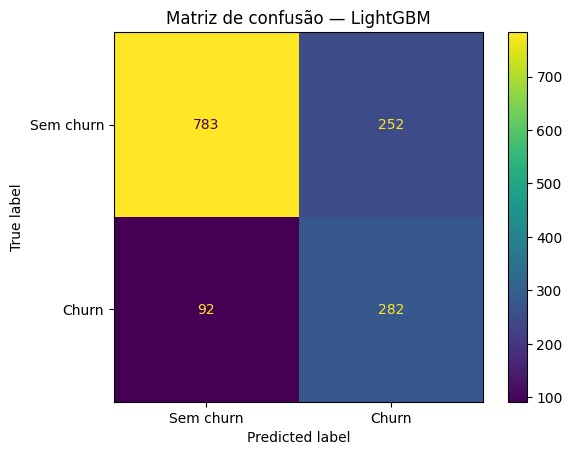

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculando a matriz de confusão
cm = confusion_matrix(y_test, y_test_pred)

# Exibindo os valores
tn, fp, fn, tp = cm.ravel()

print('Verdadeiros negativos:', tn)
print('Falsos positivos:', fp)
print('Falsos negativos:', fn)
print('Verdadeiros positivos:', tp)

# Visualização
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Sem churn', 'Churn']
)

disp.plot()
plt.title('Matriz de confusão — LightGBM')
plt.show()

### Interpretação da matriz de confusão

A matriz de confusão permite observar de forma mais concreta o desempenho do modelo LightGBM no conjunto de teste.

Entre os clientes que **não apresentaram churn**, o modelo classificou corretamente **783 clientes** como sem churn, enquanto **252 clientes** foram classificados incorretamente como clientes com risco de cancelamento.

Entre os **374 clientes que realmente apresentaram churn**, o modelo identificou corretamente **282 clientes**, enquanto **92 clientes** não foram identificados. Isso corresponde a um recall de aproximadamente **75,4%**, indicando que o modelo consegue detectar cerca de três em cada quatro clientes que efetivamente cancelam o serviço.

O número de falsos positivos é relativamente elevado, o que está relacionado ao uso do limiar de decisão de **0,30**. A redução do limiar aumenta a sensibilidade do modelo para detectar churn, mas também faz com que mais clientes sem churn sejam classificados como clientes de risco.

No contexto de retenção de clientes, esse comportamento pode ser adequado quando o custo de deixar de identificar um cliente que está prestes a cancelar é maior do que o custo de direcionar uma ação de retenção para um cliente que permaneceria na empresa.

## 20. Importância das variáveis

Após a avaliação do modelo final, será analisada a importância relativa das características utilizadas pelo LightGBM. Essa análise permite identificar quais atributos tiveram maior influência nas decisões do modelo e relacionar os resultados ao contexto de cancelamento de clientes.

In [75]:
# Recuperando o pré-processador e o modelo LightGBM treinados
final_preprocessor = final_model.named_steps['preprocessor']
final_lgbm = final_model.named_steps['model']

# Recuperando diretamente o OneHotEncoder
encoder = final_preprocessor.named_transformers_['cat']

# Criando manualmente os nomes das características categóricas
categorical_names = []

for feature, categories in zip(categorical_features, encoder.categories_):
    for category in categories:
        categorical_names.append(f'{feature}_{category}')

# Adicionando as características numéricas
feature_names = categorical_names + numeric_features

# Recuperando as importâncias do LightGBM
feature_importances = final_lgbm.feature_importances_

# Verificação
print('Número de características:', len(feature_names))
print('Número de importâncias:', len(feature_importances))

# Criando DataFrame
importance_df = pd.DataFrame({
    'Característica': feature_names,
    'Importância': feature_importances
})

# Ordenando da maior para a menor importância
importance_df = (
    importance_df
    .sort_values('Importância', ascending=False)
    .reset_index(drop=True)
)

# Exibindo as 15 características mais importantes
importance_df.head(15)

Número de características: 42
Número de importâncias: 42


,Característica,Importância
0,TotalCharges,431
1,MonthlyCharges,350
2,OnlineSecurity_No,45
3,PaperlessBilling_No,42
4,PaymentMethod_Electronic check,40
5,Type_Month-to-month,39
6,Type_Two year,38
7,MultipleLines_No,38
8,InternetService_Fiber optic,35
9,gender_Female,35


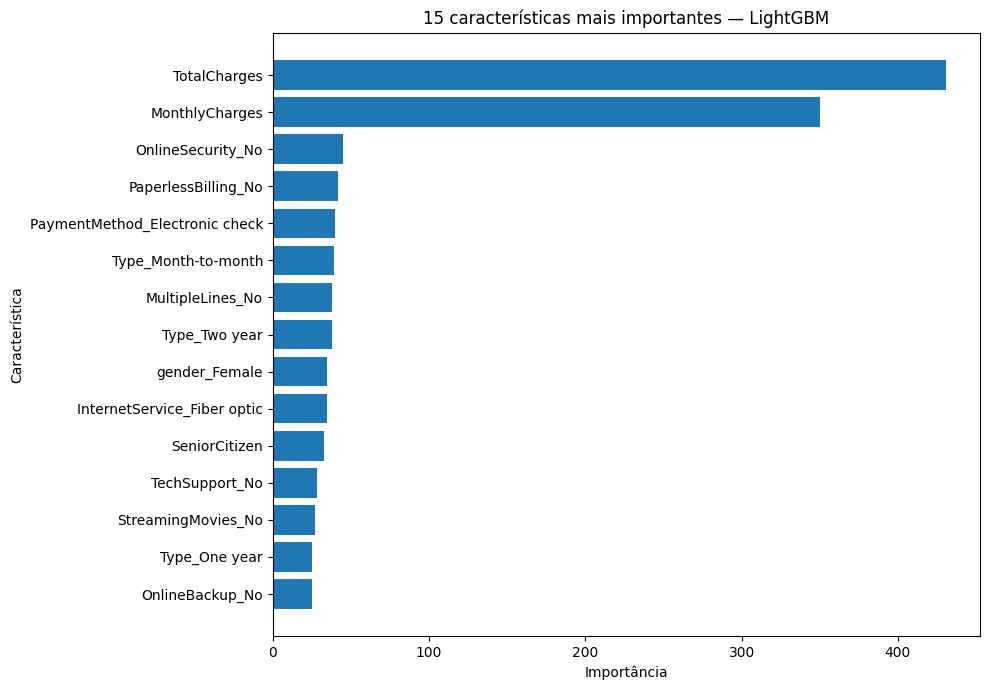

In [76]:
import matplotlib.pyplot as plt

# Selecionando as 15 características mais importantes
top_15 = importance_df.head(15).sort_values(
    'Importância',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_15['Característica'],
    top_15['Importância']
)

plt.xlabel('Importância')
plt.ylabel('Característica')
plt.title('15 características mais importantes — LightGBM')

plt.tight_layout()
plt.show()

## Interpretação das características após One-Hot Encoding

A análise de importância das características mostra que **TotalCharges** e **MonthlyCharges** foram as variáveis mais utilizadas pelo modelo LightGBM, com importâncias de **431** e **350**, respectivamente. Isso indica que as informações relacionadas aos valores financeiros dos contratos tiveram papel relevante nas decisões realizadas pelo modelo.

Outras características com importância considerável estão relacionadas ao uso de serviços, forma de cobrança e características contratuais. Entre elas aparecem **OnlineSecurity_No**, **PaperlessBilling_No**, **PaymentMethod_Electronic check**, os contratos **Month-to-month**, **One year** e **Two year**, além de **InternetService_Fiber optic** e **TechSupport_No**.

Esses resultados sugerem que o modelo utiliza uma combinação de informações financeiras, contratuais e de serviços para diferenciar clientes com diferentes probabilidades de churn.

É importante destacar que a importância das características não representa diretamente o sentido da relação com o churn. Portanto, uma característica com alta importância não significa necessariamente que ela aumenta ou reduz a probabilidade de cancelamento; significa que essa característica teve participação relevante nas decisões realizadas pelo modelo.

In [77]:
# Cópia da tabela de importâncias
importance_grouped = importance_df.copy()

# Função para recuperar o nome da variável original
def get_original_feature(feature_name):
    
    # Variáveis numéricas mantêm o próprio nome
    if feature_name in numeric_features:
        return feature_name
    
    # Variáveis categóricas geradas pelo One-Hot Encoding
    for feature in categorical_features:
        if feature_name.startswith(feature + '_'):
            return feature
    
    return feature_name


# Identificando a variável original
importance_grouped['Variável original'] = (
    importance_grouped['Característica']
    .apply(get_original_feature)
)

# Somando as importâncias das categorias da mesma variável
importance_original = (
    importance_grouped
    .groupby('Variável original', as_index=False)['Importância']
    .sum()
    .sort_values('Importância', ascending=False)
    .reset_index(drop=True)
)

print('Número de variáveis originais:', len(importance_original))

importance_original

Número de variáveis originais: 17


,Variável original,Importância
0,TotalCharges,431
1,MonthlyCharges,350
2,Type,102
3,PaymentMethod,71
4,PaperlessBilling,61
5,MultipleLines,59
6,InternetService,45
7,OnlineSecurity,45
8,gender,39
9,StreamingMovies,36


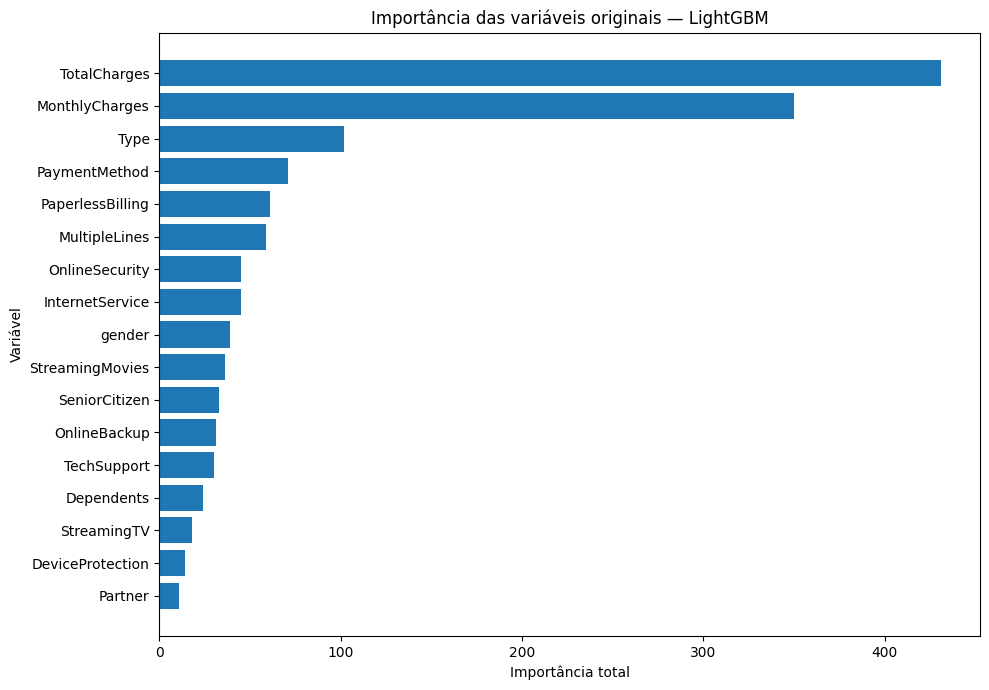

In [78]:
# Ordenando as variáveis para o gráfico
importance_plot = importance_original.sort_values(
    'Importância',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    importance_plot['Variável original'],
    importance_plot['Importância']
)

plt.xlabel('Importância total')
plt.ylabel('Variável')
plt.title('Importância das variáveis originais — LightGBM')

plt.tight_layout()
plt.show()

### Interpretação da importância das variáveis

A análise das importâncias do modelo LightGBM mostra que **TotalCharges** e **MonthlyCharges** foram as variáveis mais utilizadas pelo modelo, com importâncias de 431 e 350, respectivamente. A diferença em relação às demais características é expressiva, indicando que as informações relacionadas aos valores cobrados dos clientes tiveram papel relevante nas previsões realizadas pelo modelo.

Entre as variáveis categóricas, destacam-se **Type** (102), **PaymentMethod** (71), **PaperlessBilling** (61) e **MultipleLines** (59). Também apresentaram relevância variáveis relacionadas aos serviços contratados, como **InternetService**, **OnlineSecurity**, **StreamingMovies**, **OnlineBackup** e **TechSupport**.

Esses resultados sugerem que o comportamento previsto de churn está associado a uma combinação de aspectos financeiros, contratuais, formas de pagamento e serviços utilizados pelos clientes.

É importante destacar que a importância das características do LightGBM indica o quanto cada variável foi utilizada pelo modelo para realizar as previsões, mas não determina diretamente se uma variável aumenta ou reduz a probabilidade de churn. Portanto, os resultados devem ser interpretados como relevância preditiva, e não como uma relação causal.

## Conclusão da modelagem

Após a comparação dos modelos de Regressão Logística, Random Forest e LightGBM, o **LightGBM otimizado** foi selecionado como modelo final.

Durante a otimização, os melhores hiperparâmetros encontrados para o LightGBM foram:

- `n_estimators = 100`
- `learning_rate = 0.05`
- `num_leaves = 15`
- `class_weight = None`

Na validação cruzada, essa configuração alcançou **AUC-ROC média de 0,8477**, apresentando o melhor desempenho entre as configurações avaliadas.

Além da otimização dos hiperparâmetros, diferentes limiares de classificação foram analisados. O limiar de **0,30** foi escolhido buscando aumentar a capacidade do modelo de identificar clientes com risco de churn, mantendo um equilíbrio razoável entre precisão e recall.

No conjunto de teste, o modelo final apresentou:

- **AUC-ROC:** 0,8396
- **Acurácia:** 0,7559
- **Precisão:** 0,5281
- **Recall:** 0,7540
- **F1-score:** 0,6211

A AUC-ROC próxima à obtida durante a validação cruzada indica que o modelo manteve boa capacidade de generalização em dados não utilizados durante o treinamento.

A matriz de confusão mostrou que, entre os **374 clientes que efetivamente apresentaram churn**, o modelo identificou corretamente **282**, enquanto **92** não foram identificados. Isso corresponde ao recall de aproximadamente **75,4%**.

Por outro lado, 252 clientes que não apresentaram churn foram classificados como clientes de risco. Esse resultado representa o compromisso assumido ao utilizar um limiar de 0,30: aumentar a identificação de potenciais cancelamentos ao custo de uma maior quantidade de falsos positivos.

A análise de importância das características mostrou que **TotalCharges** e **MonthlyCharges** foram as variáveis de maior relevância para as decisões do modelo. Também se destacaram características relacionadas ao tipo de contrato, método de pagamento, faturamento e serviços contratados.

Portanto, o modelo desenvolvido apresenta capacidade satisfatória para identificar antecipadamente clientes com maior risco de churn e pode ser utilizado como ferramenta de apoio às estratégias de retenção da empresa.

## Segmentação dos clientes por nível de risco de churn

Além da classificação binária entre churn e não churn, as probabilidades previstas pelo modelo podem ser utilizadas para separar os clientes em diferentes níveis de risco.

Essa segmentação permite priorizar ações de retenção de acordo com a probabilidade estimada de cancelamento.

In [79]:
# Criando uma base para análise de risco no conjunto de teste
risk_analysis = X_test.copy()

# Probabilidade de churn calculada pelo modelo final
risk_analysis['Churn_probability'] = y_test_prob

# Churn real para comparação
risk_analysis['Churn_real'] = y_test.values

risk_analysis[
    ['Churn_probability', 'Churn_real']
].head()

,Churn_probability,Churn_real
6095,0.16,0
1046,0.07,0
6565,0.35,0
4484,0.84,0
4391,0.27,0


In [80]:
# Função para classificar o nível de risco
def classify_risk(probability):
    if probability < 0.20:
        return 'Baixo risco'
    elif probability < 0.30:
        return 'Médio risco'
    else:
        return 'Alto risco'


risk_analysis['Risk_level'] = (
    risk_analysis['Churn_probability']
    .apply(classify_risk)
)

risk_analysis[
    ['Churn_probability', 'Risk_level', 'Churn_real']
].head(10)

,Churn_probability,Risk_level,Churn_real
6095,0.16,Baixo risco,0
1046,0.07,Baixo risco,0
6565,0.35,Alto risco,0
4484,0.84,Alto risco,0
4391,0.27,Médio risco,0
3995,0.24,Médio risco,1
4724,0.07,Baixo risco,0
1735,0.04,Baixo risco,0
6539,0.17,Baixo risco,0
790,0.02,Baixo risco,0


In [81]:
risk_counts = (
    risk_analysis['Risk_level']
    .value_counts()
    .reindex(['Baixo risco', 'Médio risco', 'Alto risco'])
)

risk_counts

Baixo risco    710
Médio risco    165
Alto risco     534
Name: Risk_level, dtype: int64

In [82]:
risk_percent = (
    risk_analysis['Risk_level']
    .value_counts(normalize=True)
    .mul(100)
    .reindex(['Baixo risco', 'Médio risco', 'Alto risco'])
    .round(2)
)

risk_percent

Baixo risco   50.39
Médio risco   11.71
Alto risco    37.90
Name: Risk_level, dtype: float64

In [83]:
risk_summary = (
    risk_analysis
    .groupby('Risk_level', observed=True)
    .agg(
        Clientes=('Churn_real', 'size'),
        Churn_real=('Churn_real', 'sum'),
        Probabilidade_media=('Churn_probability', 'mean')
    )
)

risk_summary['Taxa_churn_real'] = (
    risk_summary['Churn_real'] /
    risk_summary['Clientes'] * 100
)

risk_summary = risk_summary.reindex(
    ['Baixo risco', 'Médio risco', 'Alto risco']
)

risk_summary.round(2)

,Clientes,Churn_real,Probabilidade_media,Taxa_churn_real
Risk_level,,,,
Baixo risco,710,53,0.07,7.46
Médio risco,165,39,0.25,23.64
Alto risco,534,282,0.55,52.81


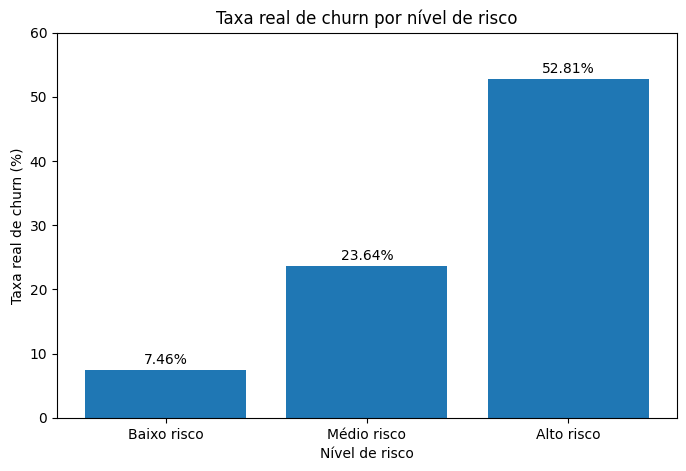

In [84]:
import matplotlib.pyplot as plt

# Dados para o gráfico
risk_plot = risk_summary.reset_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    risk_plot['Risk_level'],
    risk_plot['Taxa_churn_real']
)

# Valores acima das barras
for bar, value in zip(bars, risk_plot['Taxa_churn_real']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{value:.2f}%',
        ha='center'
    )

plt.title('Taxa real de churn por nível de risco')
plt.xlabel('Nível de risco')
plt.ylabel('Taxa real de churn (%)')
plt.ylim(0, 60)

plt.show()

### Interpretação da segmentação de risco

A segmentação dos clientes com base nas probabilidades previstas pelo modelo apresentou uma relação clara com a ocorrência real de churn.

Entre os **710 clientes classificados como baixo risco**, apenas **53 apresentaram churn**, correspondendo a uma taxa de **7,46%**. No grupo de **médio risco**, foram observados **39 casos de churn entre 165 clientes**, elevando a taxa para **23,64%**.

O grupo de **alto risco** apresentou a maior concentração de cancelamentos. Dos **534 clientes classificados nesse grupo, 282 apresentaram churn**, correspondendo a uma taxa de **52,81%**.

A taxa real de churn, portanto, aumenta de forma consistente à medida que cresce o nível de risco estimado pelo modelo: de **7,46% no grupo de baixo risco para 52,81% no grupo de alto risco**.

Esse resultado indica que as probabilidades produzidas pelo modelo são úteis não apenas para realizar uma classificação binária, mas também para priorizar clientes de acordo com o risco de cancelamento. Em um cenário de negócio, a empresa poderia concentrar inicialmente suas ações de retenção nos clientes classificados como de alto risco.

In [85]:
# Selecionando apenas os clientes classificados como alto risco
high_risk = risk_analysis[
    risk_analysis['Risk_level'] == 'Alto risco'
].copy()

print('Número de clientes de alto risco:', len(high_risk))

high_risk[
    ['MonthlyCharges', 'TotalCharges', 'Type',
     'PaymentMethod', 'InternetService',
     'OnlineSecurity']
].head()

Número de clientes de alto risco: 534


,MonthlyCharges,TotalCharges,Type,PaymentMethod,InternetService,OnlineSecurity
6565,106.20,6375.20,Month-to-month,Electronic check,Fiber optic,Yes
4484,70.35,70.35,Month-to-month,Electronic check,Fiber optic,No
5004,111.15,6953.40,Month-to-month,Electronic check,Fiber optic,No
5306,83.65,1465.75,Month-to-month,Electronic check,Fiber optic,No
512,74.35,334.80,Month-to-month,Electronic check,Fiber optic,No


In [86]:
risk_numeric_profile = (
    risk_analysis
    .groupby('Risk_level')[
        ['MonthlyCharges', 'TotalCharges']
    ]
    .mean()
    .reindex(['Baixo risco', 'Médio risco', 'Alto risco'])
)

risk_numeric_profile.round(2)

,MonthlyCharges,TotalCharges
Risk_level,,
Baixo risco,55.05,2750.18
Médio risco,77.92,3299.71
Alto risco,75.59,1313.64


In [87]:
contract_profile = pd.crosstab(
    risk_analysis['Risk_level'],
    risk_analysis['Type'],
    normalize='index'
).mul(100)

contract_profile.round(2)

Type,Month-to-month,One year,Two year
Risk_level,,,
Alto risco,94.57,5.43,0.00
Baixo risco,21.41,33.52,45.07
Médio risco,63.64,36.36,0.00


In [88]:
payment_profile = pd.crosstab(
    risk_analysis['Risk_level'],
    risk_analysis['PaymentMethod'],
    normalize='index'
).mul(100)

payment_profile.round(2)

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Risk_level,,,,
Alto risco,10.86,10.67,62.92,15.54
Baixo risco,27.46,31.27,14.37,26.90
Médio risco,30.91,23.03,32.12,13.94


In [89]:
internet_profile = pd.crosstab(
    risk_analysis['Risk_level'],
    risk_analysis['InternetService'],
    normalize='index'
).mul(100)

internet_profile.round(2)

InternetService,DSL,Fiber optic,No internet
Risk_level,,,
Alto risco,20.97,74.16,4.87
Baixo risco,43.38,20.14,36.48
Médio risco,36.36,60.00,3.64


### Perfil dos clientes com maior risco de churn

A análise dos grupos de risco mostra diferenças importantes no perfil dos clientes classificados pelo modelo.

Os clientes de **alto risco** apresentam cobrança mensal média de **75,59**, superior aos **55,05** observados no grupo de baixo risco. Entretanto, o valor total acumulado (`TotalCharges`) é consideravelmente menor no grupo de alto risco (**1.313,64**) do que nos grupos de médio (**3.299,71**) e baixo risco (**2.750,18**). Esse comportamento pode estar relacionado a clientes com menor permanência na empresa, embora essa hipótese não possa ser confirmada diretamente sem uma variável explícita de tempo de contrato.

O **tipo de contrato** apresenta uma das diferenças mais expressivas. Entre os clientes de alto risco, **94,57% possuem contrato mês a mês**, enquanto apenas **5,43% possuem contrato anual** e nenhum cliente desse grupo possui contrato de dois anos. Em comparação, no grupo de baixo risco apenas **21,41% possuem contrato mês a mês**, enquanto **45,07% possuem contrato de dois anos**.

Também existe uma forte diferença no **método de pagamento**. Entre os clientes de alto risco, **62,92% utilizam cheque eletrônico**, contra apenas **14,37% no grupo de baixo risco**. Já os métodos automáticos de pagamento são mais frequentes entre os clientes de baixo risco.

Em relação ao serviço de internet, **74,16% dos clientes de alto risco utilizam fibra óptica**, enquanto essa proporção é de apenas **20,14% entre os clientes de baixo risco**. No grupo de médio risco, a fibra óptica também apresenta participação elevada, de **60,00%**.

Portanto, o grupo classificado como de alto risco apresenta principalmente uma combinação de **contratos mensais, maior presença de pagamento por cheque eletrônico, utilização de internet por fibra óptica e cobranças mensais relativamente elevadas**.

Esses resultados não significam necessariamente que essas características causem o churn, mas mostram que elas estão fortemente associadas ao perfil que o modelo identificou como de maior risco.

## Recomendações de negócio e estratégia de retenção

### Estratégias sugeridas

Com base nas previsões do modelo e no perfil dos grupos de risco, a empresa pode utilizar a probabilidade de churn para priorizar ações de retenção.

**Clientes de alto risco**

Os clientes classificados como de alto risco devem receber maior prioridade nas campanhas de retenção. Esse grupo representa 534 clientes no conjunto de teste e apresentou uma taxa real de churn de 52,81%.

Algumas ações possíveis incluem:

- oferecer incentivos para migração de contratos mensais para contratos de maior duração;
- avaliar benefícios ou condições especiais para clientes com cobranças mensais elevadas;
- incentivar métodos automáticos de pagamento;
- investigar a experiência dos clientes que utilizam fibra óptica, já que esse serviço aparece com maior frequência no grupo de alto risco;
- oferecer suporte e ofertas de retenção direcionadas antes do cancelamento.

**Clientes de médio risco**

Esse grupo pode receber campanhas preventivas de menor custo, como comunicação personalizada, ofertas de serviços ou benefícios de fidelização.

**Clientes de baixo risco**

Como apresentam menor probabilidade de churn, esses clientes não precisam ser priorizados em campanhas de retenção mais caras. A empresa pode concentrar recursos nos grupos de maior risco.

In [90]:
# Resumo final do modelo

final_summary = pd.DataFrame({
    'Modelo': ['LightGBM'],
    'Limiar': [final_threshold],
    'AUC-ROC': [final_auc],
    'Acurácia': [final_accuracy],
    'Precisão': [final_precision],
    'Recall': [final_recall],
    'F1-score': [final_f1]
})

final_summary.round(4)

,Modelo,Limiar,AUC-ROC,Acurácia,Precisão,Recall,F1-score
0,LightGBM,0.30,0.84,0.76,0.53,0.75,0.62


In [91]:
# Resumo da segmentação dos clientes por nível de risco

risk_final_summary = pd.DataFrame({
    'Nível de risco': [
        'Baixo risco',
        'Médio risco',
        'Alto risco'
    ],
    'Clientes': [
        710,
        165,
        534
    ],
    'Churn real': [
        53,
        39,
        282
    ],
    'Taxa real de churn (%)': [
        7.46,
        23.64,
        52.81
    ]
})

risk_final_summary

,Nível de risco,Clientes,Churn real,Taxa real de churn (%)
0,Baixo risco,710,53,7.46
1,Médio risco,165,39,23.64
2,Alto risco,534,282,52.81


## Síntese dos resultados finais 

O modelo final LightGBM apresentou **AUC-ROC de 0,84**, acurácia de **0,76**, precisão de **0,53**, recall de **0,75** e F1-score de **0,62** no conjunto de teste, utilizando limiar de classificação de **0,30**.
A segmentação baseada nas probabilidades previstas apresentou comportamento consistente: a taxa real de churn aumentou de **7,46%** no grupo de baixo risco para **23,64%** no grupo de médio risco e **52,81%** no grupo de alto risco.
Os resultados indicam que o modelo pode ser utilizado tanto para identificar clientes com maior probabilidade de churn quanto para apoiar a priorização de ações de retenção.


# Conclusão Geral

O objetivo deste projeto foi desenvolver uma solução de Machine Learning capaz de identificar clientes com maior probabilidade de churn e utilizar as previsões obtidas para apoiar estratégias de retenção.

Ao longo do projeto, os dados foram analisados, preparados e transformados para o treinamento dos modelos. As variáveis categóricas foram codificadas e os dados foram separados em conjuntos de treinamento e teste, mantendo o conjunto de teste reservado para a avaliação final.

Inicialmente, foi utilizado um modelo baseline para estabelecer uma referência de desempenho. Em seguida, foram avaliados diferentes algoritmos de classificação, incluindo **Regressão Logística, Random Forest e LightGBM**, utilizando a **AUC-ROC como principal métrica de comparação**. Também foram analisados os efeitos do balanceamento das classes e realizada a otimização dos hiperparâmetros.

Após essas etapas, o **LightGBM foi selecionado como modelo final**, apresentando na validação cruzada uma AUC-ROC média de aproximadamente **0,85**. No conjunto de teste, o modelo alcançou **AUC-ROC de 0,84**, com **acurácia de 0,76, precisão de 0,53, recall de 0,75 e F1-score de 0,62**, utilizando um limiar de classificação de **0,30**.

A escolha desse limiar permitiu priorizar a identificação dos clientes com maior risco de cancelamento. Dos **374 clientes que realmente apresentaram churn**, **282 foram corretamente identificados pelo modelo**, enquanto 92 não foram detectados. Dessa forma, o modelo conseguiu identificar aproximadamente **75% dos casos reais de churn**.

A análise das probabilidades previstas também possibilitou dividir os clientes em grupos de risco. Foram classificados **710 clientes como baixo risco, 165 como médio risco e 534 como alto risco**. A taxa real de churn foi de **7,46% no grupo de baixo risco, 23,64% no grupo de médio risco e 52,81% no grupo de alto risco**, demonstrando uma clara diferença entre os segmentos identificados pelo modelo.

A análise do perfil dos clientes mostrou ainda que o grupo de alto risco apresenta forte concentração de **contratos mensais (94,57%)**, **pagamento por cheque eletrônico (62,92%)** e **serviço de internet por fibra óptica (74,16%)**. Em relação aos valores cobrados, os clientes de alto risco apresentaram cobrança mensal média de **75,59**, enquanto o grupo de baixo risco apresentou média de **55,05**.

Na análise de importância das variáveis, **TotalCharges** e **MonthlyCharges** foram as características de maior importância para o LightGBM, seguidas por informações relacionadas ao **tipo de contrato, método de pagamento, faturamento sem papel, múltiplas linhas, serviço de internet e segurança online**. Essas importâncias representam a contribuição das variáveis para as decisões do modelo e não devem ser interpretadas, isoladamente, como relações causais com o churn.

Do ponto de vista de negócio, os resultados permitem utilizar o modelo como ferramenta de apoio à priorização das ações de retenção. A empresa pode concentrar inicialmente seus esforços nos clientes classificados como **alto risco**, avaliando estratégias como ofertas de migração para contratos de maior duração, benefícios de fidelização, revisão das condições de pagamento e ações direcionadas à experiência com os serviços contratados.

Portanto, o modelo desenvolvido atende ao objetivo de **identificar clientes com maior risco de churn e transformar as previsões em informações úteis para a tomada de decisão**. A combinação entre previsão, segmentação de risco e análise do perfil dos clientes permite que as equipes de retenção direcionem seus recursos de forma mais eficiente, priorizando os clientes com maior probabilidade estimada de cancelamento.